# Практика 3. Что на самом деле говорят данные

**Ситуация.** После практики 2 руководитель филиала поверил данным и задаёт три вопроса:

1. «Старые абоненты уходят реже — значит, лояльность растёт со временем?»
2. «Кто пишет в чат, уходит реже, чем кто звонит, — давайте переводить всех в чат?»
3. «Маркетинг говорит, что программа удержания в Кургане и Нижнем Тагиле снизила отток на десятки процентов. Масштабируем на все города?»

На каждый вопрос в данных есть очевидный ответ. **Он неверный.** Ваша задача — найти верный и показать его так, чтобы руководитель понял.

**Данные:** `data/clients.csv`, `data/monthly_churn.csv`, `data/marketing_slide.png`. Описание — в `data/README.md`, прочитайте его.

> **Правило: исходные файлы не изменять.** Вся обработка — кодом. При проверке ноутбук перезапускается на оригинальных данных:
> если он упадёт или даст другие числа, балл за ноутбук не ставится.

**Сдать до 23:59 в день занятия:** тест «Практика 3» (8 баллов) и этот ноутбук (4 балла, критерии в конце).

> ИИ-ассистентами пользоваться можно. Но здесь ошибка не в коде, а в выводе: ассистент охотно посчитает
> «очевидное» и уверенно его объяснит. Проверяйте, на тот ли вопрос отвечает расчёт.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cl = pd.read_csv('data/clients.csv')
mo = pd.read_csv('data/monthly_churn.csv')
cl.head()

,client_id,city,tariff,tech,connected,contact_channel,status,churn_month
0,RT-307063,Тюмень,Базовый 100,FTTB,2022-05-08,телефон,активен,NaN
1,RT-304818,Екатеринбург,Базовый 100,FTTB,2025-08-10,чат,активен,NaN
2,RT-307190,Тюмень,Игровой 500,xPON,2019-09-29,нет обращений,активен,NaN
3,RT-301401,Тюмень,Семейный 300,xPON,2019-02-18,чат,активен,NaN
4,RT-303631,Тюмень,Базовый 100,ADSL,2018-12-05,телефон,активен,NaN


In [2]:
mo.head()

,month,city,active_start,churned
0,2026-01,Екатеринбург,2276,26
1,2026-02,Екатеринбург,2250,26
2,2026-03,Екатеринбург,2224,21
3,2026-04,Екатеринбург,2203,40
4,2026-05,Екатеринбург,2163,22


In [3]:
# Дата подключения уже есть в connected. Стаж — это расстояние от неё до одной общей точки.
# Точка фиксирована заданием: 1 января 2026. В этот день все из выгрузки ещё были активны.
cl['connected'] = pd.to_datetime(cl['connected'])

# Сначала разница в днях: так легче проверить глазами, что число похоже на правду.
# 365.25 — средняя длина года с високосными. Получается стаж в годах на контрольную дату.
cl['tenure'] = (pd.Timestamp('2026-01-01') - cl['connected']).dt.days / 365.25

# Для ответа на этот пункт достаточно смотреть две колонки.
# Из cl их не удаляем: следующий вопрос той же части считает долю расторгнувших, а она лежит в status.
cl[['client_id', 'tenure']].head()


,client_id,tenure
0,RT-307063,3.652293
1,RT-304818,0.394251
2,RT-307190,6.258727
3,RT-301401,6.869268
4,RT-303631,7.074606


## Часть 1. Стаж и отток (вопросы 1–3)

1. Посчитайте стаж абонента **на 1 января 2026 года** в годах.
2. Сравните долю расторгнувших у абонентов со стажем больше 5 лет и меньше 1 года.
3. Постройте **график 1**: доля оттока (%) по группам стажа (например, <1, 1–2, 2–3, 3–5, >5 лет). Подпишите над столбцами число абонентов в группе.
4. Перечитайте в README, **кто попал в выгрузку**. Почему это важно для вопроса руководителя?

In [13]:
# Одно число не бывает сразу больше 5 и меньше 1. В фразе «и» здесь две разные группы.
# Квадратные скобки оставляют строки по условию. filter() так не умеет: он смотрит имена столбцов.
old = cl[cl['tenure'] > 5]
young = cl[cl['tenure'] < 1]

# Сравниваем не списки id, а долю расторгнувших внутри каждой группы.
# True/False в среднем даёт долю: 1 — расторгнут, 0 — нет.
print('количество абонентов больше 5 лет,', (old['status'] == 'расторгнут').count())
print('количество абонентов меньше 1 года,', (young['status'] == 'расторгнут').count())

print('количество ушедших абонентов больше 5 лет,', (old['status'] == 'расторгнут').sum())
print('количество ушедших абонентов меньше 1 года,', (young['status'] == 'расторгнут').sum())


# count() считает все непустые значения, и False тоже. Поэтому выше выходит не число ушедших,
# а размер группы: 3032 и 1330. Значит, здесь 3032 / 1330 ≈ 2.28 — во сколько раз старых
# абонентов больше, чем новых. Про отток это ничего не говорит.
# Ушедших считает sum() (True = 1), долю — mean(). Отношение долей: около 0.65,
# то есть у старых доля оттока примерно в 1.5 раза ниже:
# (old['status'] == 'расторгнут').mean() / (young['status'] == 'расторгнут').mean()

print('отношение количества абонентов больше 5 лет к количеству абонентов меньше 1 года,', (old['status'] == 'расторгнут').count() / (young['status'] == 'расторгнут').count())


количество абонентов больше 5 лет, 3032
количество абонентов меньше 1 года, 1330
количество ушедших абонентов больше 5 лет, 263
количество ушедших абонентов меньше 1 года, 177
отношение количества абонентов больше 5 лет к количеству абонентов меньше 1 года, 2.2796992481203007


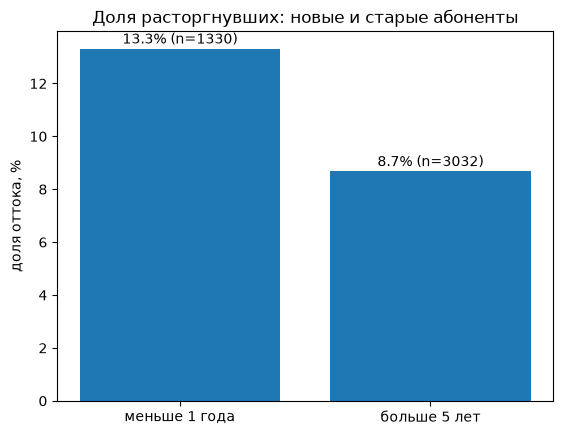

In [12]:
# На графике сравниваем доли, а не количества: группы разного размера (3032 и 1330).
# mean() от True/False — доля ушедших, умножаем на 100, чтобы были проценты.
shares = [(young['status'] == 'расторгнут').mean() * 100,
          (old['status'] == 'расторгнут').mean() * 100]
sizes = [len(young), len(old)]
names = ['меньше 1 года', 'больше 5 лет']

plt.bar(names, shares)
# Подпись над столбцом: сама доля и сколько абонентов за ней стоит.
for i in range(2):
    plt.text(i, shares[i] + 0.2, f'{shares[i]:.1f}% (n={sizes[i]})', ha='center')
plt.title('Доля расторгнувших: новые и старые абоненты')
plt.ylabel('доля оттока, %')
plt.show()

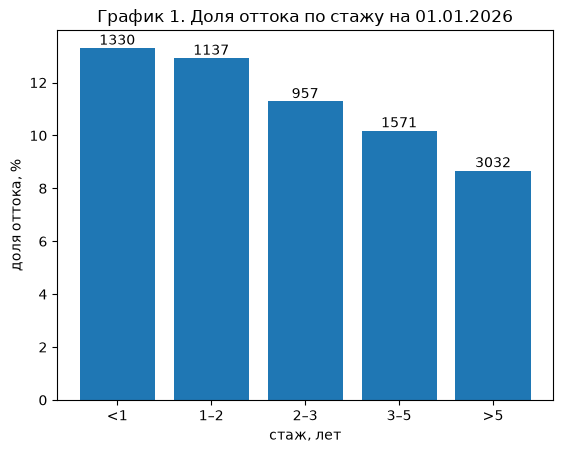

In [23]:
# Доля оттока = ушедшие / все в группе. Поэтому берём ВСЕХ абонентов, а не только ушедших:
# без знаменателя получится просто число ушедших, а оно больше там, где больше людей.
cl['churned'] = cl['status'] == 'расторгнут'

# Та же идея, что столбцы True/False по каждой группе, только одним столбцом с названием группы.
# pd.cut раскладывает стаж по корзинам: (-1, 1], (1, 2], ... Правая граница входит, левая нет.
# Левая граница -1, чтобы не потерять стаж 0; 100 — потолок с запасом.
# Защита от подгонки: границы взяты из задания и зафиксированы ДО того, как посмотрели на результат.
# Не меняем их, если график «не понравился». Устойчивость к другим границам проверяем в следующей ячейке.
cl['tenure_group'] = pd.cut(cl['tenure'], bins=[-1, 1, 2, 3, 5, 100],
                            labels=['<1', '1–2', '2–3', '3–5', '>5'])

# mean от True/False — это доля; size — сколько абонентов в группе (это и подписываем).
churn_share = cl.groupby('tenure_group')['churned'].mean() * 100
group_size = cl.groupby('tenure_group').size()
# print(pd.DataFrame({'доля оттока, %': churn_share.round(1), 'абонентов': group_size}))

bars = plt.bar(churn_share.index.astype(str), churn_share)
# над каждым столбцом пишем, сколько абонентов в группе
plt.bar_label(bars, group_size)
plt.title('График 1. Доля оттока по стажу на 01.01.2026')
plt.xlabel('стаж, лет')
plt.ylabel('доля оттока, %')
plt.show()


In [18]:
print(cl['tenure_group'])

0       3–5
1        <1
2        >5
3        >5
4        >5
       ... 
8022    1–2
8023     <1
8024    1–2
8025    2–3
8026     >5
Name: tenure_group, Length: 8027, dtype: category
Categories (5, str): ['<1' < '1–2' < '2–3' < '3–5' < '>5']


In [20]:
print(group_size)

tenure_group
<1     1330
1–2    1137
2–3     957
3–5    1571
>5     3032
dtype: int64


In [22]:
churn_share

tenure_group
<1     13.308271
1–2    12.928760
2–3    11.285266
3–5    10.184596
>5      8.674142
Name: churned, dtype: float64

In [14]:
# Проверка устойчивости: тот же расчёт при других разумных границах.
# Если доля оттока падает со стажем при любом разбиении, вывод не создан выбором коробок.
# Если картина переворачивается — это главный результат, и о нём пишем в записке.
# Показываем все варианты, а не только удачный.
other_bins = [
    [-1, 1, 2, 3, 5, 100],              # как в задании
    [-1, 1, 2, 3, 4, 5, 6, 7, 100],     # по каждому году
    [-1, 2, 4, 6, 100],                 # крупнее, по два года
    [-1, 0.5, 1, 3, 100],               # мельче в начале
]
for b in other_bins:
    groups = pd.cut(cl['tenure'], bins=b)
    shares = cl.groupby(groups, observed=True)['churned'].mean() * 100
    print(b, shares.round(1).tolist())

# Ограничение, которое никакие границы не исправят: в выгрузке только активные на 01.01.2026.
# Кто ушёл в первые годы, среди «старых» уже нет. Поэтому это не доказательство роста лояльности.


[-1, 1, 2, 3, 5, 100] [13.3, 12.9, 11.3, 10.2, 8.7]
[-1, 1, 2, 3, 4, 5, 6, 7, 100] [13.3, 12.9, 11.3, 10.9, 9.3, 9.5, 9.1, 8.1]
[-1, 2, 4, 6, 100] [13.1, 11.1, 9.4, 8.4]
[-1, 0.5, 1, 3, 100] [13.7, 12.9, 12.2, 9.2]


## Часть 2. Канал обращений (вопросы 4–6)

1. Сравните долю оттока у обращавшихся через чат и по телефону.
2. Теперь сделайте то же **отдельно для ADSL и для остальных технологий**.
3. Постройте **график 2**: доля оттока по каналу (чат / телефон) **в разрезе технологии** — так, чтобы было видно, почему общая картина обманывает.
4. Как устроен этот эффект? Посмотрите, какой канал предпочитают абоненты ADSL и каков у них отток.

## Часть 3. Программа удержания (вопросы 7–8)

1. Посчитайте помесячную долю оттока (%) для двух групп: **пилот** (Курган + Нижний Тагил) и **остальные города**. Доля группы за месяц = сумма `churned` / сумма `active_start` по её городам.
2. Постройте **график 3**: две линии по месяцам, начало программы отмечено вертикальной линией.
3. Посчитайте для каждой группы: среднее помесячных долей за июль–октябрь минус среднее за январь–июнь.
4. Что из этого — эффект программы, а что произошло бы и без неё?

## Часть 4. Слайд отдела маркетинга

Откройте `data/marketing_slide.png`. Найдите **не меньше трёх** проблем: что на слайде вводит в заблуждение и почему.
Для каждой — как было бы честно.

*Проблемы слайда и как было бы честно:*

1. 
2. 
3. 


## Вопросы для теста

| № | Вопрос |
|---|---|
| 1 | Доля расторгнувших среди абонентов со стажем **больше 5 лет** на 01.01.2026, % |
| 2 | Доля расторгнувших среди абонентов со стажем **меньше 1 года** на 01.01.2026, % |
| 3 | Что можно утверждать о связи стажа и оттока по этим данным? (выбор ответа) |
| 4 | Доля расторгнувших среди абонентов с основным каналом «чат», % |
| 5 | Доля расторгнувших среди абонентов с основным каналом «телефон», % |
| 6 | Среди абонентов ADSL: доля оттока у «телефона» минус доля у «чата», п.п. |
| 7 | Пилотные города: изменение среднемесячной доли оттока (июль–октябрь минус январь–июнь), п.п. |
| 8 | Оценка эффекта программы методом разности разностей, п.п. |

**Вопрос 1**

**Вопрос 2**

**Вопрос 3**

In [7]:
# вопрос с выбором ответа: ответ в тесте, здесь — расчёт, который его подтверждает

**Вопрос 4**

**Вопрос 5**

**Вопрос 6**

**Вопрос 7**

**Вопрос 8**

## Записка руководителю

5–8 предложений: ответы на три вопроса руководителя с числами из ваших расчётов и графиков.
Что из «очевидного» неверно и почему; что можно и чего нельзя утверждать по этим данным; что вы предложили бы сделать.

*Ваша записка:*



## Для тех, кто закончил раньше (в зачёт активности)

Насколько надёжна оценка эффекта программы? Посчитайте разность разностей **отдельно для каждого пилотного города** против остальных городов.
Совпадают ли оценки? Что бы вы сказали руководителю о решении масштабировать программу?

## Как оценивается ноутбук (4 балла)

- 1 — ноутбук перезапускается на оригинальных данных без ошибок (Kernel → Restart Kernel and Run All Cells);
- 1 — три графика: подписаны оси с единицами, у графика 1 — число абонентов, у графика 3 — отмечено начало программы;
- 1 — разбор слайда маркетинга: не меньше трёх проблем, у каждой — как было бы честно;
- 1 — записка руководителю: ответы на три вопроса с числами и ограничениями.